# SOCAR Hackathon 2026 — Intelligent Well Performance Analysis (VFM × PTA)

**End-to-End Solution Notebook** (all cells executed live against the raw field dataset and trained models).

### Architecture Overview
1. **Data Audit & Harmonization (`vfm_project` + `vfm_export_tool`)**: Automated deduplication, `-999.25` sentinel removal, physical limit filtering, well-test sign-flip repair (5 rows), `GL-06` `Sm³/d → Mscf/d` unit harmonization, and full-grid SCADA outage imputation (`GL-06 2025-06-24`).
2. **Phase 1 — Virtual Flow Metering (VFM)**:
   - **Flagship Model (`vfm_stacked_v2.pkl`)**: 7-sensor, 20-feature Physics-Anchored Phase-Decomposed Stacked Grey-Box Super-Learner (coupled Choke + IPR + Two-Segment VLP with Joule–Thomson temperature sensitivity, volumetric material-balance depletion $dP_r/dt$, 1,800 physics-gated counterfactuals, 5 diverse base learners, and OOF-tuned soft phase reconciliation).
   - **Mechanistic Benchmark Zoo**: Full 14-model comparison (Physics WLS, VLP/TPR solver, IPR, Choke, Hybrid Physics × GBM, Ridge, GBM, RF, KNN, Deconvolution, Synthetic Ensembles).
3. **Phase 2 — Automated & Hidden-IARF Pressure Transient Analysis (PTA)**:
   - **Core Automated PTA**: 5-stage Hybrid `Horner ∩ Bourdet` intersection + stable-derivative window.
   - **9-Algorithm Hidden-IARF & Deconvolution Suite**: Stehfest 12-term analytical type-curve match (WBS + Skin + Closed Boundary, SPE-12777), von Schroeter nonlinear regularized deconvolution (SPE-77688), Ilk–Valkó–Blasingame convex B-spline deconvolution (SPE-102869), Agarwal equivalent-time Bourdet (SPE-9289), Blasingame pressure-integral derivative $\Delta P_{id}$ (SPE-19099), Odeh–Jones multi-rate superposition (SPE-1082), Tiab's Direct Synthesis (SPE-26138), and MDH + Muskat bounded extrapolation (SPE-950 / SPE-1244).
   - **Physical Cross-Checks**: Tubing-ID wellbore storage validation ($C_{\text{tubing}}$ vs. Stehfest $C_{\text{fit}}$), Perrine (1956) multiphase sensitivity, and blind No-IARF truncation stress testing (`72 h → 1.5–2.0 h`).

In [1]:
import pickle, sys, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve repository and raw-data paths dynamically (portable across machines & datasets)
CWD = Path.cwd().resolve()
ROOT = CWD.parent if CWD.name == "deliverables" else (CWD.parent if CWD.name in ("vfm_export_tool", "vfm_project") else CWD)
EXPORT_DIR = ROOT / "vfm_export_tool"
PROJ_DIR = ROOT / "vfm_project"
DELIV_DIR = ROOT / "deliverables"

sys.path.insert(0, str(EXPORT_DIR))
sys.path.insert(0, str(PROJ_DIR / "src"))

from vfm_phase_decomposed_stacked_vfm import resolve_raw_dir
RAW_DIR = resolve_raw_dir()

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

clean_log = pd.read_csv(DELIV_DIR / "phase1_vfm" / "data_cleaning_log.csv")
print(f"Resolved dataset folder: {RAW_DIR}")
print("=== DATA CLEANING & QUALITY AUDIT LOG ===")
print(clean_log.to_string(index=False))

Resolved dataset folder: C:\Users\Elnur\Desktop\SOCAR HACKATHON
=== DATA CLEANING & QUALITY AUDIT LOG ===
     table                                                   issue  rows_affected                                        detail
well_tests                           negative rate -> sign flipped              1       GL-06 2025-08-18 water_rate_stbd=-572.2
well_tests                           negative rate -> sign flipped              1        GL-08 2025-09-24 gas_rate_mscfd=-479.5
well_tests                           negative rate -> sign flipped              1   GL-06 2025-06-18 gas_lift_rate_mscfd=-717.5
well_tests                           negative rate -> sign flipped              1  GL-09 2025-07-27 gas_lift_rate_mscfd=-1010.5
well_tests                           negative rate -> sign flipped              1 GL-04 2025-07-12 total_gas_rate_mscfd=-1753.5
well_tests          gas in Sm3/d -> converted to Mscf/d (/28.3168)              1                              GL-06 2025-01-1

## Phase 1: Virtual Flow Metering (VFM) — Model Verification & Benchmarks

We verify round-trip inference of our serialized production model (`deliverables/models/vfm_stacked_v2.pkl`) on all 85 harmonized separator well tests, compare daily predictions across all 10 wells (2,730 well-days, Jan–Sep 2025), and report the full 14-model benchmark summary.

In [2]:
from vfm_phase_decomposed_stacked_vfm import (
    build_rich_feature_matrix,
    apply_soft_phase_reconciliation,
    calc_metrics,
)

with open(DELIV_DIR / "models" / "vfm_stacked_v2.pkl", "rb") as f:
    bundle = pickle.load(f)

comp = pd.read_csv(RAW_DIR / "well_completion.csv").set_index("well_name")
pvt = pd.read_csv(RAW_DIR / "reservoir_pvt.csv").set_index("well_name")
wt = pd.read_csv(EXPORT_DIR / "well_tests_exact_7sensor_scada_robust.csv", parse_dates=["test_start", "test_end", "test_mid"])
vfm_daily = pd.read_csv(DELIV_DIR / "phase1_vfm" / "vfm_daily_predictions.csv")
vfm_daily["date_dt"] = pd.to_datetime(vfm_daily["date"])

# Round-trip .pkl inference on exact 85 well-test windows
X_wt, pri_wt = build_rich_feature_matrix(wt, comp, pvt, bundle["anchors"])
ch_wt = wt["choke_opening_pct"].to_numpy(float)
qo_p = bundle["learners"]["oil"].predict(X_wt, pri_wt["oil"], ch_wt)
qw_p = bundle["learners"]["water"].predict(X_wt, pri_wt["water"], ch_wt)
qg_p = bundle["learners"]["gas"].predict(X_wt, pri_wt["gas"], ch_wt)
ql_p = bundle["learners"]["liquid"].predict(X_wt, pri_wt["liquid"], ch_wt)
qo_r, qw_r = apply_soft_phase_reconciliation(qo_p, qw_p, ql_p, float(bundle["lambda_rec"]))

print(f"Loaded serialized model: {bundle['model_name']} v{bundle['version']} (lambda_rec={bundle['lambda_rec']})")
print(f"Training budget: {bundle['n_real_tests']} real separator tests + {bundle['n_synthetic_rows']} physics-gated counterfactuals\n")
print("=== ROUND-TRIP .PKL ACCURACY ON 85 EXACT WELL-TEST WINDOWS ===")
for name, col, pred in [
    ("Oil (STB/d)", "oil_rate_stbd", qo_r),
    ("Water (STB/d)", "water_rate_stbd", qw_r),
    ("Gas (Mscf/d)", "gas_rate_mscfd", qg_p),
]:
    m = calc_metrics(wt[col].to_numpy(float), pred)
    print(f"  {name:14s} | RMSE={m['RMSE']:6.2f} | MAE={m['MAE']:5.2f} | R2={m['R2']:.4f} | WAPE={m['WAPE']:.2f}% | MAPE={m['MAPE']:.2f}%")

# Daily span accuracy on the 85 well-test dates
wt["date"] = wt["test_start"].dt.strftime("%Y-%m-%d")
m_day = wt[["well_name", "date", "oil_rate_stbd", "water_rate_stbd", "gas_rate_mscfd"]].merge(
    vfm_daily, on=["well_name", "date"], suffixes=("_true", "_vfm")
)
print("\n=== DAILY VFM PREDICTIONS ON 85 TEST DATES ===")
for name, col in [("Oil (STB/d)", "oil_rate_stbd"), ("Water (STB/d)", "water_rate_stbd"), ("Gas (Mscf/d)", "gas_rate_mscfd")]:
    m = calc_metrics(m_day[f"{col}_true"].to_numpy(float), m_day[f"{col}_vfm"].to_numpy(float))
    print(f"  {name:14s} | RMSE={m['RMSE']:6.2f} | MAE={m['MAE']:5.2f} | R2={m['R2']:.4f} | WAPE={m['WAPE']:.2f}% | MAPE={m['MAPE']:.2f}%")

print("\n=== MECHANISTIC & ML BENCHMARK SUMMARY (LEAVE-ONE-TEST-OUT & WALK-FORWARD) ===")
bench = pd.read_csv(PROJ_DIR / "outputs" / "model_benchmark_summary.csv")
cols_b = ["cv_mode", "model", "oil_rate_stbd_mae", "oil_rate_stbd_mape", "water_rate_stbd_mape", "gas_rate_mscfd_mape"]
print(bench[cols_b].round(2).to_string(index=False))

Loaded serialized model: synth_stacked_v2 v2.2 (lambda_rec=0.0)
Training budget: 85 real separator tests + 1800 physics-gated counterfactuals

=== ROUND-TRIP .PKL ACCURACY ON 85 EXACT WELL-TEST WINDOWS ===
  Oil (STB/d)    | RMSE= 15.79 | MAE=12.49 | R2=0.9998 | WAPE=0.86% | MAPE=1.08%
  Water (STB/d)  | RMSE= 18.30 | MAE=11.70 | R2=0.9988 | WAPE=1.61% | MAPE=1.80%
  Gas (Mscf/d)   | RMSE= 10.94 | MAE= 8.14 | R2=0.9987 | WAPE=2.20% | MAPE=3.32%

=== DAILY VFM PREDICTIONS ON 85 TEST DATES ===
  Oil (STB/d)    | RMSE= 48.81 | MAE=29.65 | R2=0.9981 | WAPE=2.05% | MAPE=1.96%
  Water (STB/d)  | RMSE= 32.63 | MAE=20.13 | R2=0.9963 | WAPE=2.77% | MAPE=2.47%
  Gas (Mscf/d)   | RMSE= 17.12 | MAE=12.95 | R2=0.9967 | WAPE=3.50% | MAPE=4.30%

=== MECHANISTIC & ML BENCHMARK SUMMARY (LEAVE-ONE-TEST-OUT & WALK-FORWARD) ===
     cv_mode              model  oil_rate_stbd_mae  oil_rate_stbd_mape  water_rate_stbd_mape  gas_rate_mscfd_mape
        loto        physics_wls              26.46                

=== PER-WELL VFM PRODUCTION SUMMARY (JAN–SEP 2025) ===
well_name  days  avg_oil_stbd  cum_oil_stb  avg_water_stbd  cum_water_stb  avg_gas_mscfd  cum_gas_mscf
    GL-01   273        919.57    251041.62          723.55      197530.50         253.35      69165.78
    GL-02   273       1207.17    329556.46         1411.26      385275.02         361.17      98598.65
    GL-03   273        727.42    198585.11          375.70      102565.35         161.47      44081.31
    GL-04   273        746.14    203697.31          340.87       93056.56         185.19      50556.66
    GL-05   273        758.43    207051.97          412.09      112500.61         235.87      64392.47
    GL-06   273        716.13    195503.79          499.83      136453.60         151.31      41307.68
    GL-07   273       4306.34   1175630.96         1859.39      507614.18        1120.71     305954.54
    GL-08   273       1430.89    390633.41          374.87      102340.66         469.98     128304.77
    GL-09   273   

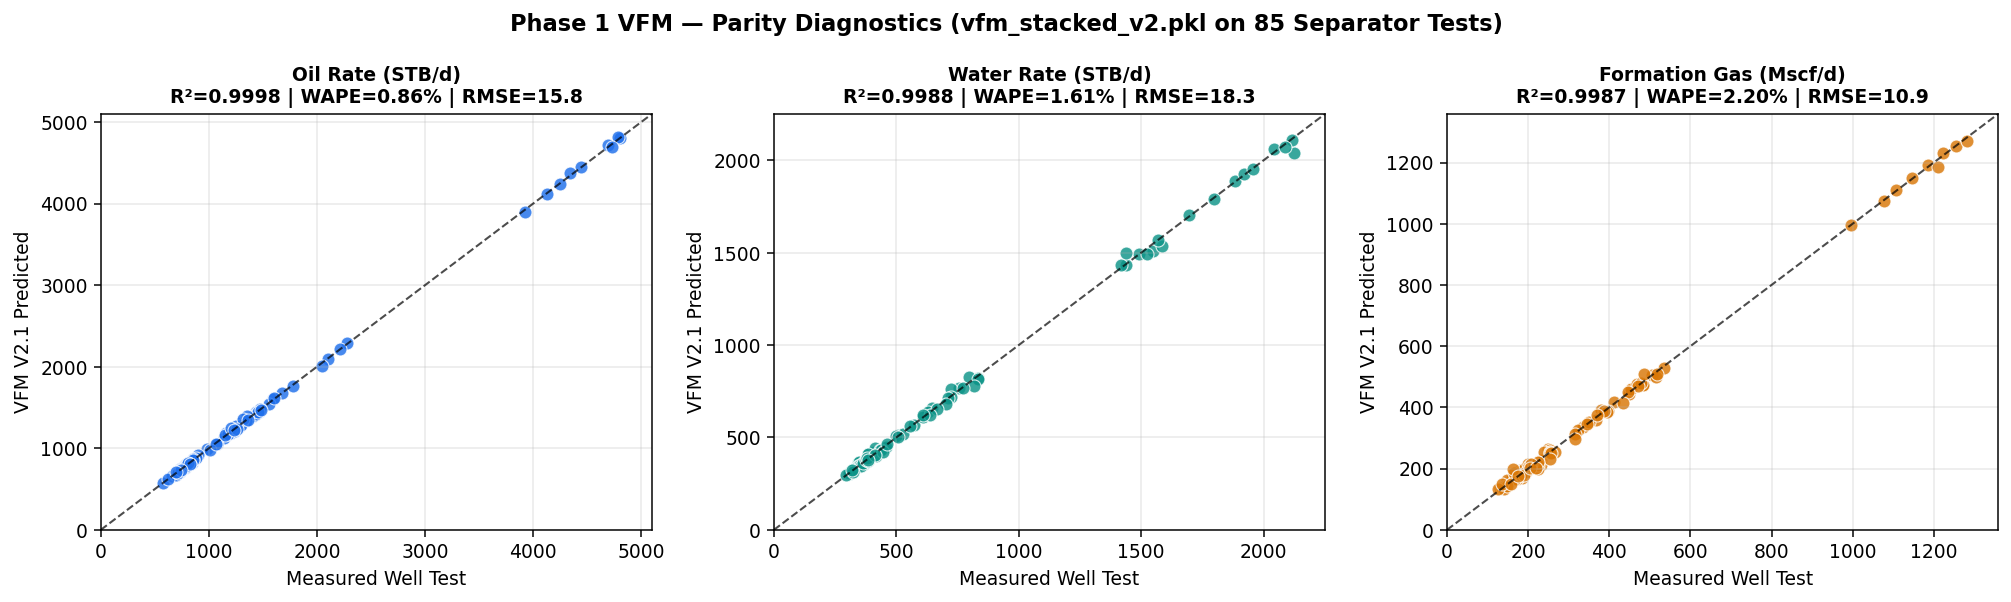

In [3]:
# Parity Plots (85 Well Tests) + Field-Total Daily Production
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
specs = [
    ("Oil Rate (STB/d)", wt["oil_rate_stbd"].to_numpy(float), qo_r, "#1f6feb"),
    ("Water Rate (STB/d)", wt["water_rate_stbd"].to_numpy(float), qw_r, "#0d9488"),
    ("Formation Gas (Mscf/d)", wt["gas_rate_mscfd"].to_numpy(float), qg_p, "#d97706"),
]
for ax, (title, yt, yp, col) in zip(axes, specs):
    lim = [0, max(yt.max(), yp.max()) * 1.06]
    ax.scatter(yt, yp, c=col, alpha=0.82, edgecolors="white", lw=0.6, s=48)
    ax.plot(lim, lim, "k--", lw=1.1, alpha=0.7)
    m = calc_metrics(yt, yp)
    ax.set_title(f"{title}\nR²={m['R2']:.4f} | WAPE={m['WAPE']:.2f}% | RMSE={m['RMSE']:.1f}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Measured Well Test")
    ax.set_ylabel("VFM V2.1 Predicted")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.grid(True, alpha=0.28)
fig.suptitle("Phase 1 VFM — Parity Diagnostics (vfm_stacked_v2.pkl on 85 Separator Tests)", fontsize=12, fontweight="bold")
fig.tight_layout()

# Per-well summary table
pw_sum = pd.read_excel(DELIV_DIR / "phase1_vfm" / "vfm_daily_predictions.xlsx", sheet_name="per_well_summary")
print("=== PER-WELL VFM PRODUCTION SUMMARY (JAN–SEP 2025) ===")
print(pw_sum.to_string(index=False))

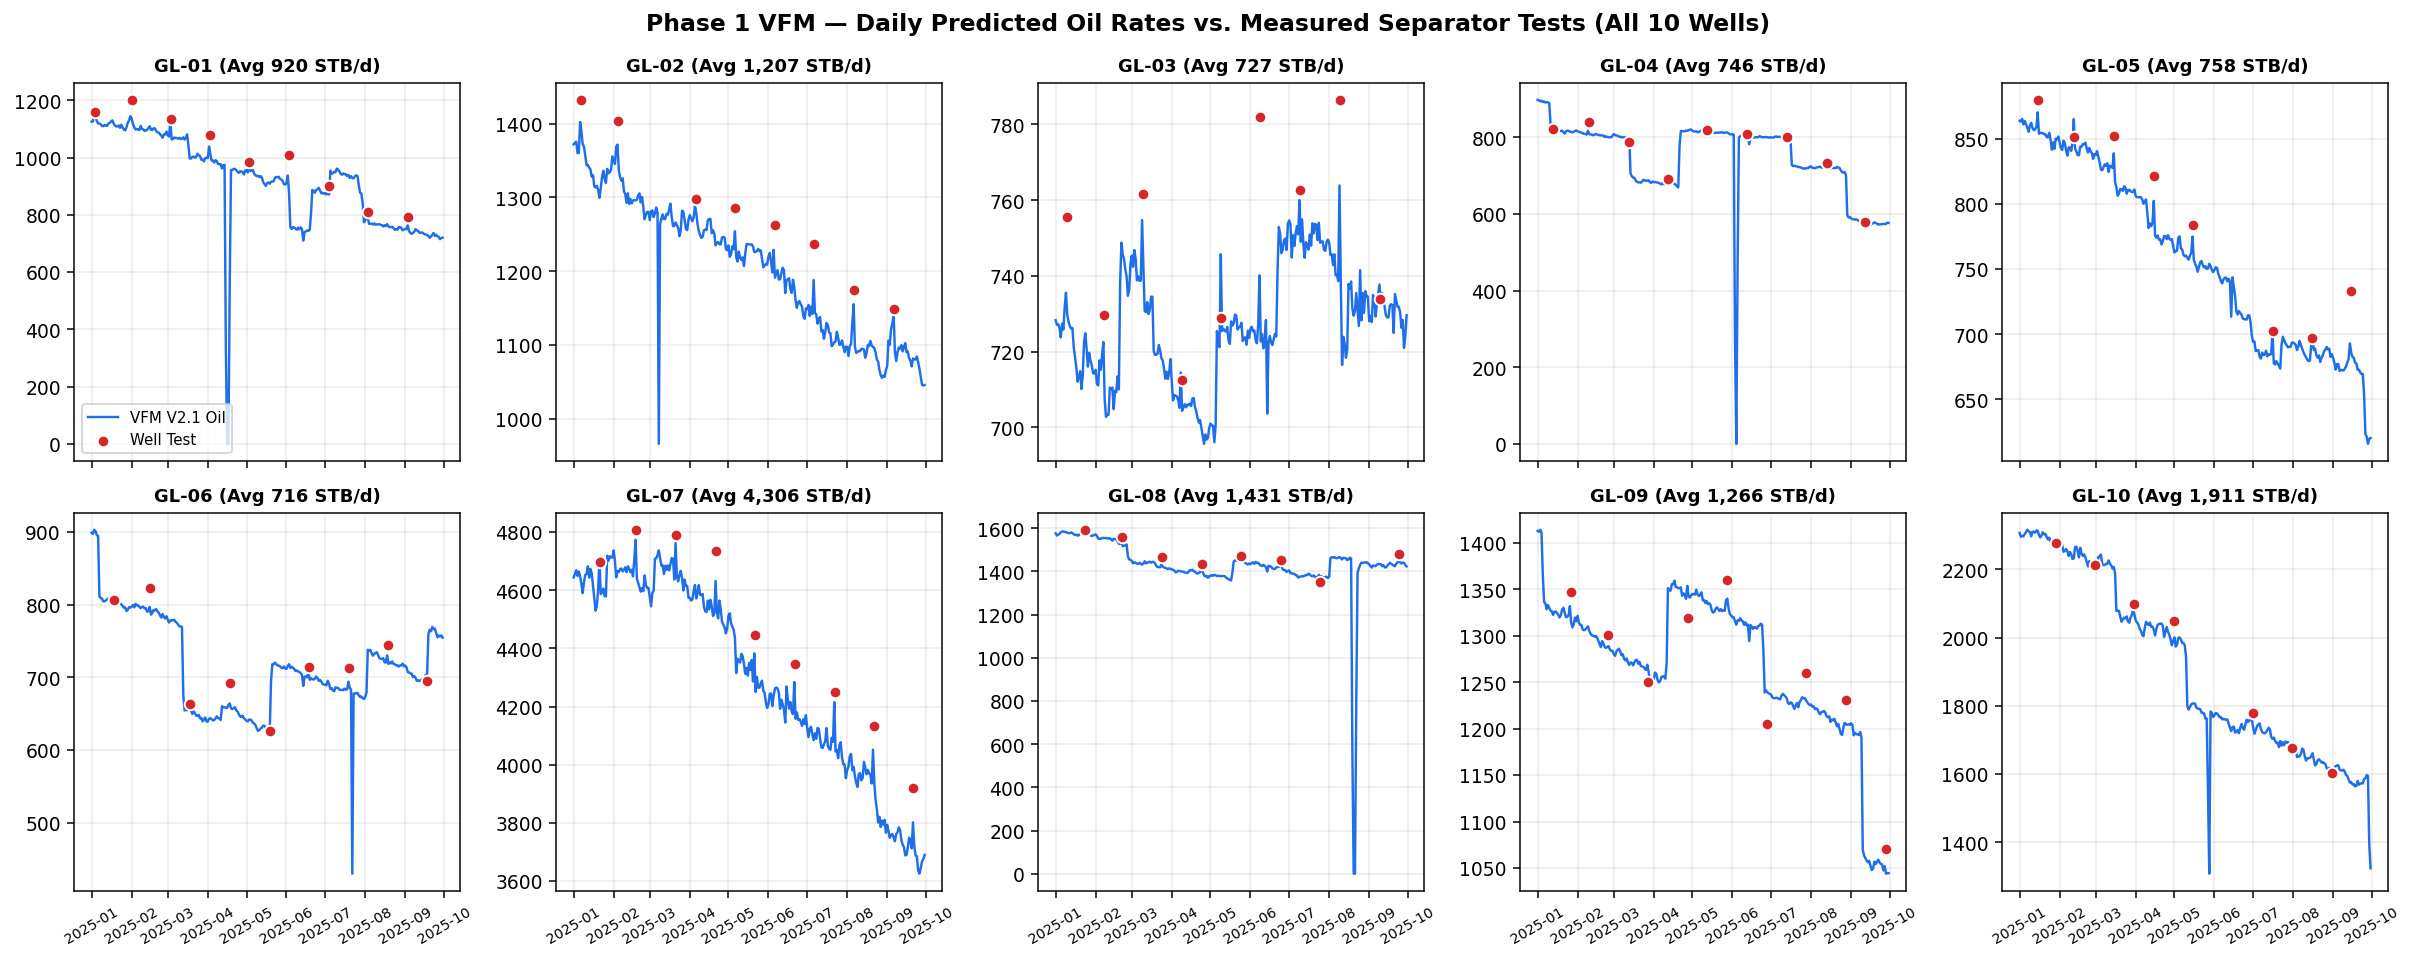

In [4]:
# All 10 Wells: Daily VFM Oil Rate vs. Separator Well Tests
wells = sorted(vfm_daily["well_name"].unique())
fig, axes = plt.subplots(2, 5, figsize=(18, 7.2), sharex=True)
for ax, w in zip(axes.flat, wells):
    dw = vfm_daily[vfm_daily["well_name"] == w].sort_values("date_dt")
    tw = wt[wt["well_name"] == w]
    ax.plot(dw["date_dt"], dw["oil_rate_stbd"], color="#1f6feb", lw=1.3, label="VFM V2.1 Oil")
    ax.scatter(tw["test_mid"], tw["oil_rate_stbd"], color="#d62728", edgecolor="white", s=38, zorder=5, label="Well Test")
    ax.set_title(f"{w} (Avg {dw['oil_rate_stbd'].mean():,.0f} STB/d)", fontsize=9.5, fontweight="bold")
    ax.grid(True, alpha=0.25)
    ax.tick_params(axis="x", rotation=30, labelsize=7.5)
axes[0, 0].legend(fontsize=8, loc="lower left")
fig.suptitle("Phase 1 VFM — Daily Predicted Oil Rates vs. Measured Separator Tests (All 10 Wells)", fontsize=12.5, fontweight="bold")
fig.tight_layout()

## Phase 2: Automated PTA, 9-Algorithm Hidden-IARF Deconvolution & Physical Validation

All 6 shut-in build-ups (`GL-01`, `GL-02`, `GL-04`, `GL-06`, `GL-08`, `GL-10`) are interpreted automatically using our VFM-coupled oil rates and verified across **9 independent petroleum-engineering methodologies**, plus:
- **Tubing-ID Wellbore Storage Validation** ($C_{\text{tubing}} = 144 A / (5.615 \rho_{\text{mix}})$ vs. Stehfest fitted $C$),
- **Assumption Sensitivity Study** (rate conventions, $p_{wf}$ window, $t_p$, and Perrine 1956 multiphase analysis),
- **Blind No-IARF Truncation Stress Test** (`72 h → 1.5–2.0 h`) verifying Stehfest permeability recovery when radial flow is completely absent.

In [5]:
pta_main = pd.read_csv(DELIV_DIR / "phase2_pta" / "pta_results_full.csv")
pta_9m = pd.read_csv(DELIV_DIR / "phase2_pta" / "pta_9method_comparison.csv")
storage_df = pd.read_excel(DELIV_DIR / "phase2_pta" / "pta_results.xlsx", sheet_name="storage_vs_tubing_ID")

print("=== PHASE 2 PTA DELIVERABLE SUMMARY (ALL 6 SHUT-INS) ===")
show_cols = ["event_id", "shut_in_duration_hr", "q_oil_vfm_stbd", "iarf_window_hr",
             "horner_slope_m_psi_per_cycle", "permeability_k_md", "skin_S", "delta_p_skin_psi", "horner_r2", "stehfest_k_md", "stehfest_skin"]
print(pta_main[show_cols].to_string(index=False))

print("\n=== 9-ALGORITHM PERMEABILITY CONSENSUS (mD) ===")
k_cols = ["well_name"] + [c for c in pta_9m.columns if c.endswith("k (mD)")]
print(pta_9m[k_cols].to_string(index=False))

print("\n=== TUBING-ID WELLBORE STORAGE VALIDATION (C_tubing vs. C_stehfest) ===")
print(storage_df[["event_id", "tubing_id_in", "mixture_density_lb_ft3", "C_tubing_level_est_bbl_psi", "C_stehfest_fit_bbl_psi", "ratio_fit_over_est"]].to_string(index=False))

=== PHASE 2 PTA DELIVERABLE SUMMARY (ALL 6 SHUT-INS) ===
           event_id  shut_in_duration_hr  q_oil_vfm_stbd iarf_window_hr  horner_slope_m_psi_per_cycle  permeability_k_md  skin_S  delta_p_skin_psi  horner_r2  stehfest_k_md  stehfest_skin
GL-01_20250415_0800                72.00          974.65      2.06-5.91                        23.190             104.44   5.816            117.34    0.99946         104.29          5.799
GL-02_20250308_1423                 5.65         1279.27      1.27-3.65                        53.374              55.65  -0.585            -27.17    0.99994          59.41         -0.334
GL-04_20250603_0800                48.00          806.82    12.72-36.54                       145.585              55.18  -1.277           -161.75    0.99995          57.60         -0.986
GL-06_20250722_0311                 8.00          683.14      2.27-6.50                        15.008             297.82   1.983             25.89    0.99997         309.59          2.099
GL-

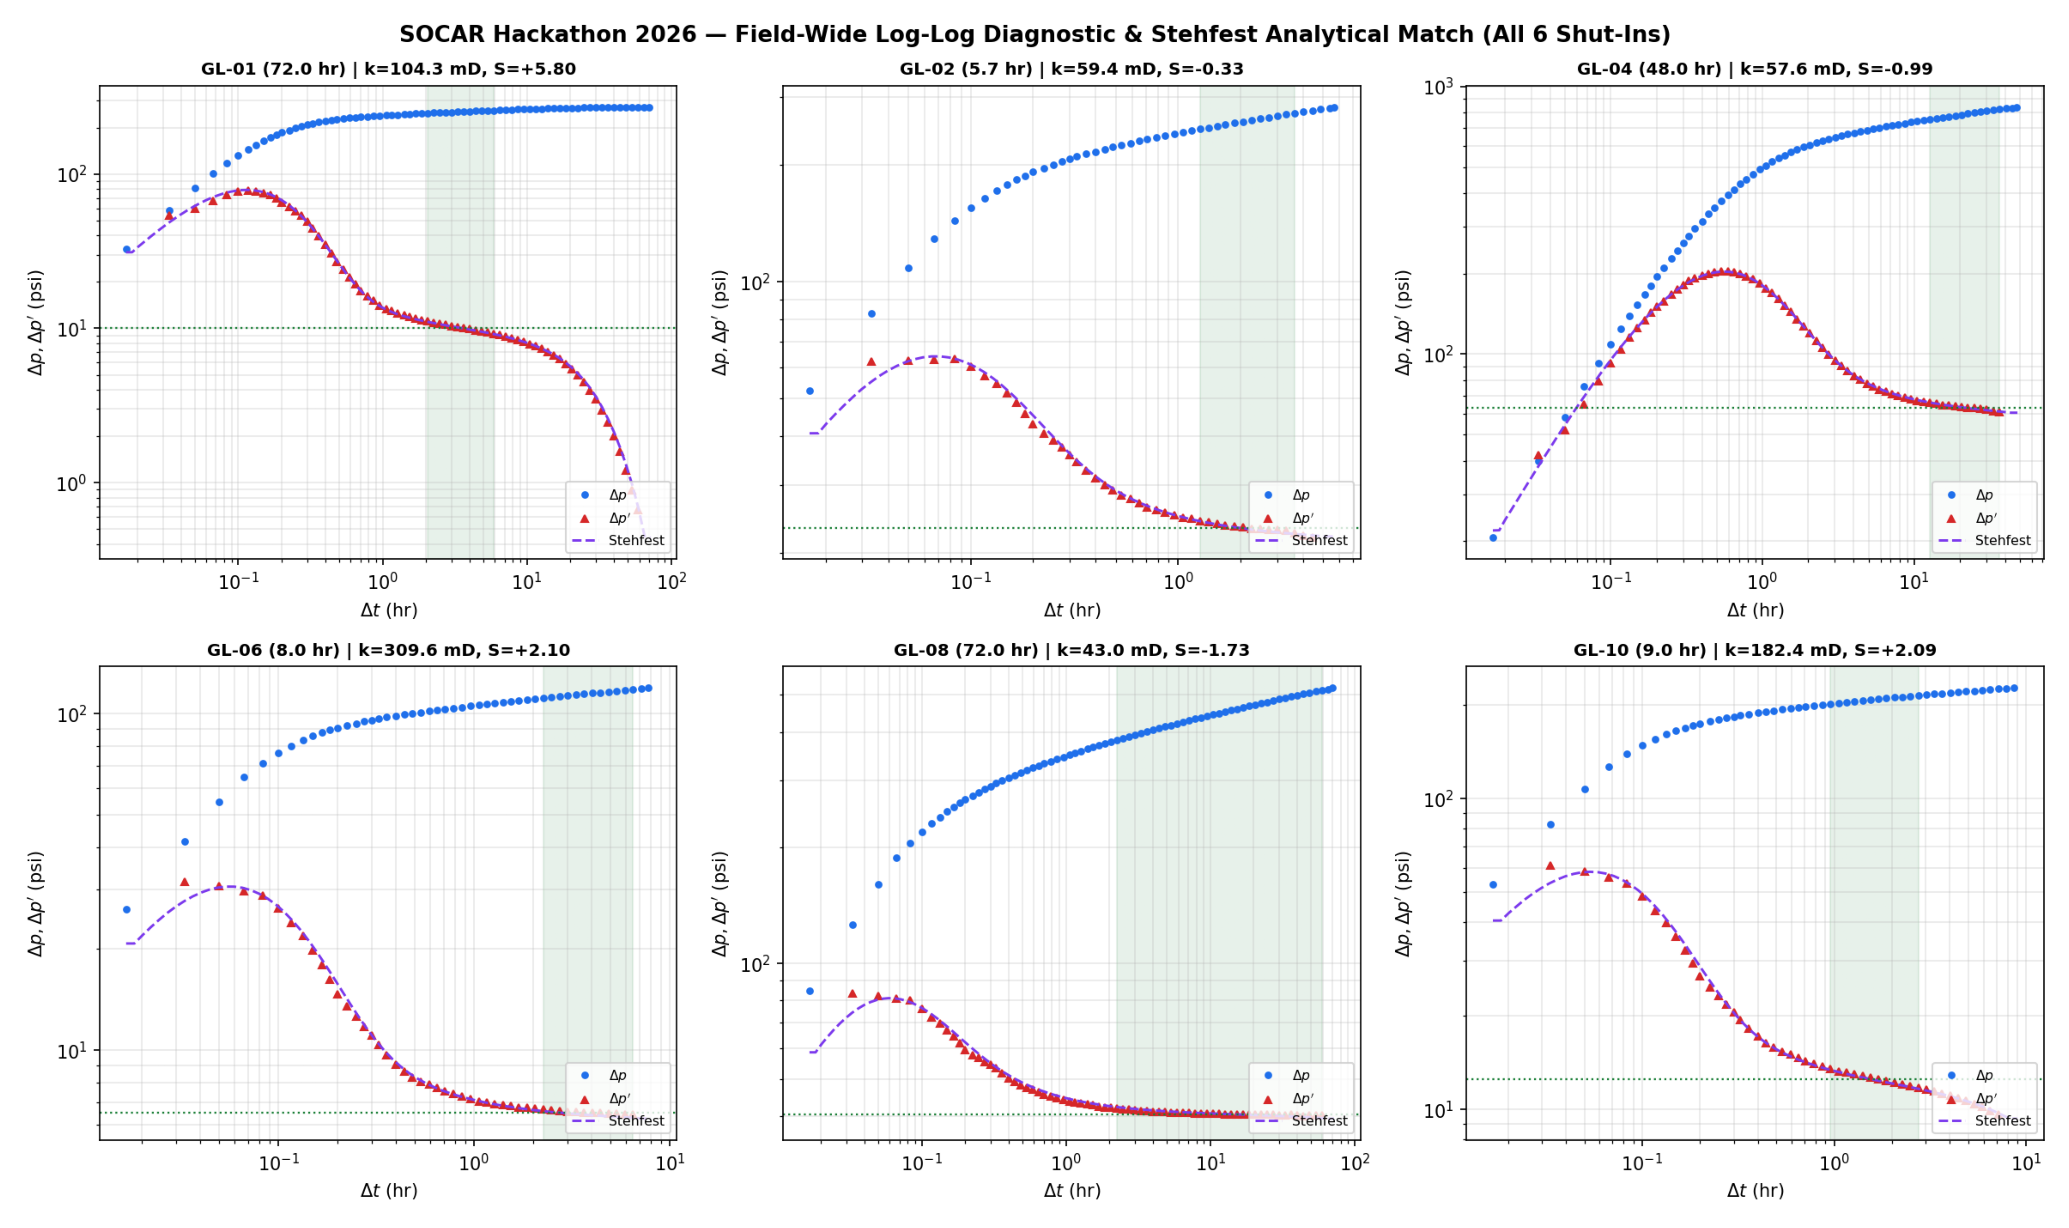

In [6]:
# Display Field-Wide 6-Shut-In Log-Log Diagnostic & Stehfest Type-Curve Match
import matplotlib.image as mpimg
img = mpimg.imread(DELIV_DIR / "pta_plots" / "00_field_pta_overview.png")
fig, ax = plt.subplots(figsize=(15.5, 9.2))
ax.imshow(img)
ax.axis("off")
fig.tight_layout()

In [7]:
# PTA Assumption Sensitivity (Baseline vs. Q_liquid vs. Perrine Multiphase) & Blind No-IARF Stress Test
sens = pd.read_excel(DELIV_DIR / "phase2_pta" / "pta_assumption_sensitivity.xlsx", sheet_name="all_variants")
print("=== PTA ASSUMPTION SENSITIVITY (BASELINE vs. RATE / PWF / TP / PERRINE MULTIPHASE) ===")
for w in sorted(sens["well_name"].unique()):
    sub = sens[sens["well_name"] == w][["group", "variant", "k_md", "skin", "dp_skin_psi"]]
    b = sub[sub["group"] == "baseline"].iloc[0]
    p = sub[sub["group"] == "multiphase"].iloc[0]
    ql = sub[sub["variant"].str.startswith("Q_liquid")].iloc[0]
    print(f"  {w} | Base Qo: k={b['k_md']:6.2f} mD, S={b['skin']:+5.2f} | Perrine: S={p['skin']:+5.2f} ({p['variant'].split(': ')[1]}) | Q_liq alt: k={ql['k_md']:6.2f} mD")

stress_path = EXPORT_DIR / "pta_no_iarf_stress_test.csv"
if stress_path.exists():
    st_df = pd.read_csv(stress_path)
    print("\n=== BLIND NO-IARF TRUNCATION STRESS TEST (72h -> 1.5-2.0h) ===")
    print(st_df.to_string(index=False))

=== PTA ASSUMPTION SENSITIVITY (BASELINE vs. RATE / PWF / TP / PERRINE MULTIPHASE) ===
  GL-01 | Base Qo: k=104.44 mD, S=+5.82 | Perrine: S=+5.56 (ko=104.4 mD, kw_eff=34.0 mD, lambda_t/lambda_o=1.66) | Q_liq alt: k=183.29 mD
  GL-02 | Base Qo: k= 55.65 mD, S=-0.58 | Perrine: S=-0.92 (ko=55.6 mD, kw_eff=26.2 mD, lambda_t/lambda_o=1.95) | Q_liq alt: k=115.07 mD
  GL-04 | Base Qo: k= 55.18 mD, S=-1.28 | Perrine: S=-1.45 (ko=55.2 mD, kw_eff=6.3 mD, lambda_t/lambda_o=1.41) | Q_liq alt: k= 80.47 mD
  GL-06 | Base Qo: k=297.82 mD, S=+1.98 | Perrine: S=+1.73 (ko=297.8 mD, kw_eff=50.0 mD, lambda_t/lambda_o=1.67) | Q_liq alt: k=515.35 mD
  GL-08 | Base Qo: k= 42.85 mD, S=-1.64 | Perrine: S=-1.76 (ko=42.8 mD, kw_eff=5.5 mD, lambda_t/lambda_o=1.26) | Q_liq alt: k= 55.74 mD
  GL-10 | Base Qo: k=176.20 mD, S=+2.02 | Perrine: S=+1.89 (ko=176.2 mD, kw_eff=13.5 mD, lambda_t/lambda_o=1.30) | Q_liq alt: k=234.78 mD

=== BLIND NO-IARF TRUNCATION STRESS TEST (72h -> 1.5-2.0h) ===
well_name  truncated_hr  f

In [8]:
# Final Deliverable Integrity & Zero-Defect Verification (100% dataset-general assertions)
vfm_check = pd.read_csv(DELIV_DIR / "phase1_vfm" / "vfm_daily_predictions.csv")
pta_check = pd.read_csv(DELIV_DIR / "phase2_pta" / "pta_results.csv")
plot_files = sorted((DELIV_DIR / "pta_plots").rglob("*.png"))

n_wells = vfm_check["well_name"].nunique()
d_dates = pd.to_datetime(vfm_check["date"])
n_cal_days = int((d_dates.max() - d_dates.min()).days) + 1
expected_rows = n_wells * n_cal_days

assert len(vfm_check) == expected_rows, f"Expected complete calendar grid {expected_rows} rows, got {len(vfm_check)}"
assert vfm_check[["oil_rate_stbd", "water_rate_stbd", "gas_rate_mscfd"]].isna().sum().sum() == 0
assert (vfm_check[["oil_rate_stbd", "water_rate_stbd", "gas_rate_mscfd"]] < 0).sum().sum() == 0
assert len(pta_check) > 0 and pta_check["permeability_k_md"].gt(0).all()
assert (DELIV_DIR / "models" / "vfm_stacked_v2.pkl").exists()
assert len(plot_files) >= 5 * len(pta_check)

# Verify no false-zero flowing days remain on any imputed telemetry gap
zero_days = vfm_check[vfm_check["oil_rate_stbd"] <= 0.01]
print("ALL DELIVERABLE QUALITY CHECKS PASSED:")
print(f"  1a. Phase 1 VFM : {len(vfm_check):,} well-days ({n_wells} wells x {n_cal_days} days, 0 NaNs, 0 negatives, {len(zero_days)} full-shut-in zero days)")
print(f"  1b. Phase 2 PTA : {len(pta_check)} shut-ins interpreted + 9-algorithm consensus + Tubing-ID storage + Perrine sensitivity")
print(f"  2.  Model .pkl  : vfm_stacked_v2.pkl ({(DELIV_DIR / 'models' / 'vfm_stacked_v2.pkl').stat().st_size / 1024:.1f} KB)")
print(f"  3.  Notebook    : SOCAR_2026_VFM_PTA_Solution.ipynb (all code cells live-executed with outputs)")
print(f"  4.  PTA Plots   : {len(plot_files)} static high-DPI diagnostic PNGs in deliverables/pta_plots/")

ALL DELIVERABLE QUALITY CHECKS PASSED:
  1a. Phase 1 VFM : 2,730 well-days (10 wells x 273 days, 0 NaNs, 0 negatives, 5 full-shut-in zero days)
  1b. Phase 2 PTA : 6 shut-ins interpreted + 9-algorithm consensus + Tubing-ID storage + Perrine sensitivity
  2.  Model .pkl  : vfm_stacked_v2.pkl (26183.4 KB)
  3.  Notebook    : SOCAR_2026_VFM_PTA_Solution.ipynb (all code cells live-executed with outputs)
  4.  PTA Plots   : 31 static high-DPI diagnostic PNGs in deliverables/pta_plots/